# Step 1: Importing Libraries

Here we import all the libraries needed for this project.
We use sklearn for loading the dataset, building the model
and evaluating results. Matplotlib is used for visualizing
the handwritten digit images.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully")

All libraries imported successfully


# Step 2: Loading the MNIST Dataset

MNIST is a dataset of 70,000 handwritten digit images.
Each image is 28x28 pixels which gives us 784 values per image
(28 multiplied by 28 equals 784 pixel values).
Each pixel value is between 0 and 255 where 0 is black
and 255 is white. We load this dataset directly from sklearn
so no manual download is needed.

This cell may take 1 to 2 minutes on first run as it 
downloads the dataset automatically.

In [2]:
print("Loading MNIST dataset, please wait...")

mnist = fetch_openml('mnist_784', version=1, as_frame=False)

X = mnist.data
y = mnist.target

print("Dataset loaded successfully")
print("Total images:", X.shape[0])
print("Pixels per image:", X.shape[1])
print("Sample labels:", y[:10])

Loading MNIST dataset, please wait...
Dataset loaded successfully
Total images: 70000
Pixels per image: 784
Sample labels: ['5' '0' '4' '1' '9' '2' '1' '3' '1' '4']


# Step 3: Visualizing Sample Images

Before training the model we want to actually see what 
the handwritten digits look like. Here we display 10 
sample images from the dataset along with their labels.
This helps us understand what the model will be learning from.

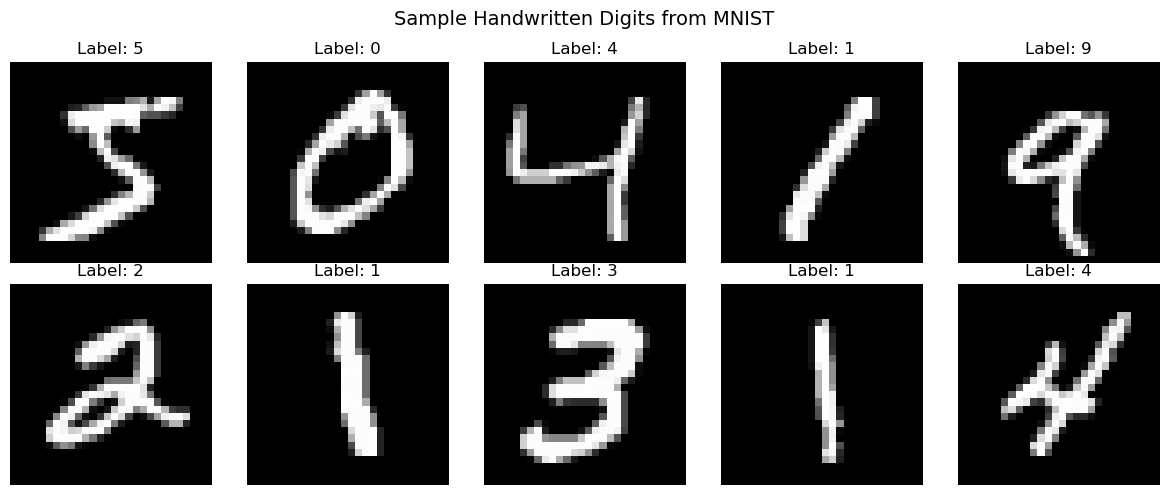

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

for i in range(10):
    image = X[i].reshape(28, 28)
    axes[i].imshow(image, cmap='gray')
    axes[i].set_title('Label: ' + str(y[i]))
    axes[i].axis('off')

plt.suptitle('Sample Handwritten Digits from MNIST', fontsize=14)
plt.tight_layout()
plt.show()

# Step 4: Checking Label Distribution

Here we check how many images exist for each digit 
from 0 to 9. A balanced dataset means each digit has 
a similar number of samples which helps the model 
learn all digits equally well.

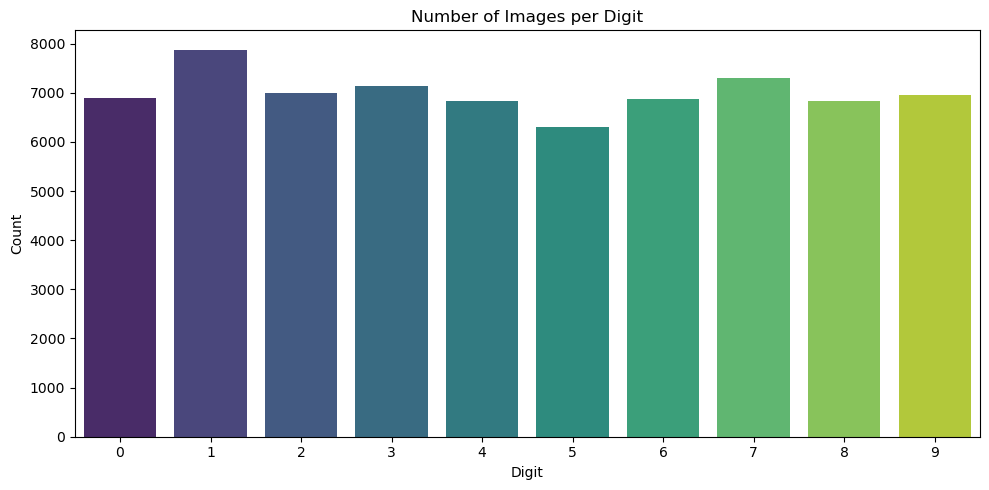

Digit distribution:
  Digit 0 : 6903 images
  Digit 1 : 7877 images
  Digit 2 : 6990 images
  Digit 3 : 7141 images
  Digit 4 : 6824 images
  Digit 5 : 6313 images
  Digit 6 : 6876 images
  Digit 7 : 7293 images
  Digit 8 : 6825 images
  Digit 9 : 6958 images


In [4]:
unique, counts = np.unique(y, return_counts=True)

plt.figure(figsize=(10, 5))
sns.barplot(x=unique, y=counts, palette='viridis')
plt.title('Number of Images per Digit')
plt.xlabel('Digit')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

print("Digit distribution:")
for digit, count in zip(unique, counts):
    print(f"  Digit {digit} : {count} images")

# Step 5: Normalizing the Pixel Values

Each image has 784 pixel values ranging from 0 to 255.
We divide all values by 255 to bring them into a range 
of 0 to 1. This is called normalization and it helps 
the model learn faster and more accurately. Without this 
large pixel values would slow down and confuse the model.

In [5]:
X = X / 255.0

print("Normalization done")
print("Pixel value range before: 0 to 255")
print("Pixel value range after : 0 to 1")
print("Min value:", X.min())
print("Max value:", X.max())

Normalization done
Pixel value range before: 0 to 255
Pixel value range after : 0 to 1
Min value: 0.0
Max value: 1.0


# Step 6: Splitting the Data into Training and Testing Sets

We use 80% of the data for training and 20% for testing.
Since we have 70,000 images that gives us 56,000 images 
for training and 14,000 for testing. We also convert the 
labels from strings to integers so the model can process them.

In [7]:
y = y.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data split done")
print("Training images :", X_train.shape[0])
print("Testing images  :", X_test.shape[0])
print("Image size      :", X_train.shape[1], "pixels per image")

Data split done
Training images : 56000
Testing images  : 14000
Image size      : 784 pixels per image


# Step 7: Scaling the Features

Even after normalization we apply StandardScaler to make 
sure all pixel values are on the same scale. This further 
improves the performance of the MLP neural network which 
is sensitive to the scale of input values.

In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaling done")
print("Mean of training data:", round(X_train.mean(), 4))
print("Std of training data :", round(X_train.std(), 4))

Scaling done
Mean of training data: 0.0
Std of training data : 0.957


# Step 8: Training the MLP Neural Network

MLP (Multi Layer Perceptron) is a neural network that learns 
patterns from pixel values. We use two hidden layers with 256 
and 128 neurons. The model will go through the training data 
multiple times (called epochs) to gradually improve its accuracy.
We train on 10,000 samples to keep training time reasonable 
while still achieving good accuracy.

In [9]:
X_train_small = X_train[:10000]
y_train_small = y_train[:10000]

mlp_model = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    activation='relu',
    max_iter=50,
    random_state=42,
    verbose=True,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5
)

print("Training started, please wait...")
mlp_model.fit(X_train_small, y_train_small)

mlp_accuracy = mlp_model.score(X_test, y_test) * 100
print("\nTraining complete")
print(f"Test Accuracy: {mlp_accuracy:.2f}%")

Training started, please wait...
Iteration 1, loss = 0.65427941
Validation score: 0.913000
Iteration 2, loss = 0.18703455
Validation score: 0.932000
Iteration 3, loss = 0.10519731
Validation score: 0.927000
Iteration 4, loss = 0.06335247
Validation score: 0.937000
Iteration 5, loss = 0.03936342
Validation score: 0.940000
Iteration 6, loss = 0.02357193
Validation score: 0.939000
Iteration 7, loss = 0.01496558
Validation score: 0.937000
Iteration 8, loss = 0.00986394
Validation score: 0.939000
Iteration 9, loss = 0.00703832
Validation score: 0.939000
Iteration 10, loss = 0.00518124
Validation score: 0.942000
Iteration 11, loss = 0.00407386
Validation score: 0.943000
Iteration 12, loss = 0.00330785
Validation score: 0.944000
Iteration 13, loss = 0.00278572
Validation score: 0.941000
Iteration 14, loss = 0.00235874
Validation score: 0.943000
Iteration 15, loss = 0.00204180
Validation score: 0.942000
Iteration 16, loss = 0.00179539
Validation score: 0.944000
Iteration 17, loss = 0.00156404


# Step 9: Training the Random Forest Model

Random Forest builds multiple decision trees and combines 
their predictions. We use 100 trees here. For image data 
Random Forest is generally slower and less accurate than 
MLP but we train it for comparison purposes.
We use the same 10,000 training samples for fair comparison.

In [10]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest, please wait...")
rf_model.fit(X_train_small, y_train_small)

rf_accuracy = rf_model.score(X_test, y_test) * 100
print("Training complete")
print(f"Test Accuracy: {rf_accuracy:.2f}%")

Training Random Forest, please wait...
Training complete
Test Accuracy: 94.46%


# Step 10: Comparing Both Models

Here we compare the accuracy of both models side by side
to see which one performs better on handwritten digit recognition.

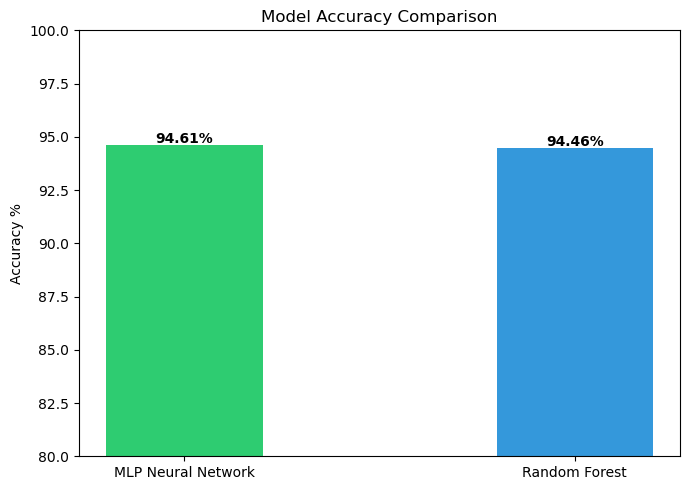

Best model  : MLP Neural Network
Best accuracy: 94.61%


In [11]:
model_names = ['MLP Neural Network', 'Random Forest']
accuracies = [mlp_accuracy, rf_accuracy]

plt.figure(figsize=(7, 5))
bars = plt.bar(model_names, accuracies, color=['#2ecc71', '#3498db'], width=0.4)
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy %')
plt.ylim(80, 100)

for bar, acc in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f'{acc:.2f}%',
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

best = model_names[np.argmax(accuracies)]
print("Best model  :", best)
print(f"Best accuracy: {max(accuracies):.2f}%")

# Step 11: Detailed Classification Report

Here we look at precision, recall and f1-score for each 
digit separately. This tells us which digits the model 
recognizes easily and which ones it sometimes confuses 
with other digits.

In [12]:
mlp_pred = mlp_model.predict(X_test)

print("Classification Report - MLP Neural Network")
print("=" * 55)
print(classification_report(y_test, mlp_pred))

Classification Report - MLP Neural Network
              precision    recall  f1-score   support

           0       0.95      0.99      0.97      1381
           1       0.97      0.98      0.98      1575
           2       0.95      0.93      0.94      1398
           3       0.93      0.94      0.93      1428
           4       0.95      0.94      0.94      1365
           5       0.93      0.93      0.93      1263
           6       0.97      0.97      0.97      1375
           7       0.94      0.95      0.95      1459
           8       0.94      0.92      0.93      1365
           9       0.92      0.93      0.92      1391

    accuracy                           0.95     14000
   macro avg       0.95      0.95      0.95     14000
weighted avg       0.95      0.95      0.95     14000



# Step 12: Confusion Matrix

The confusion matrix shows exactly which digits are being 
confused with each other. For example digit 4 and digit 9 
look similar in handwriting so the model might sometimes 
confuse them. The diagonal shows correct predictions and 
off diagonal cells show mistakes.

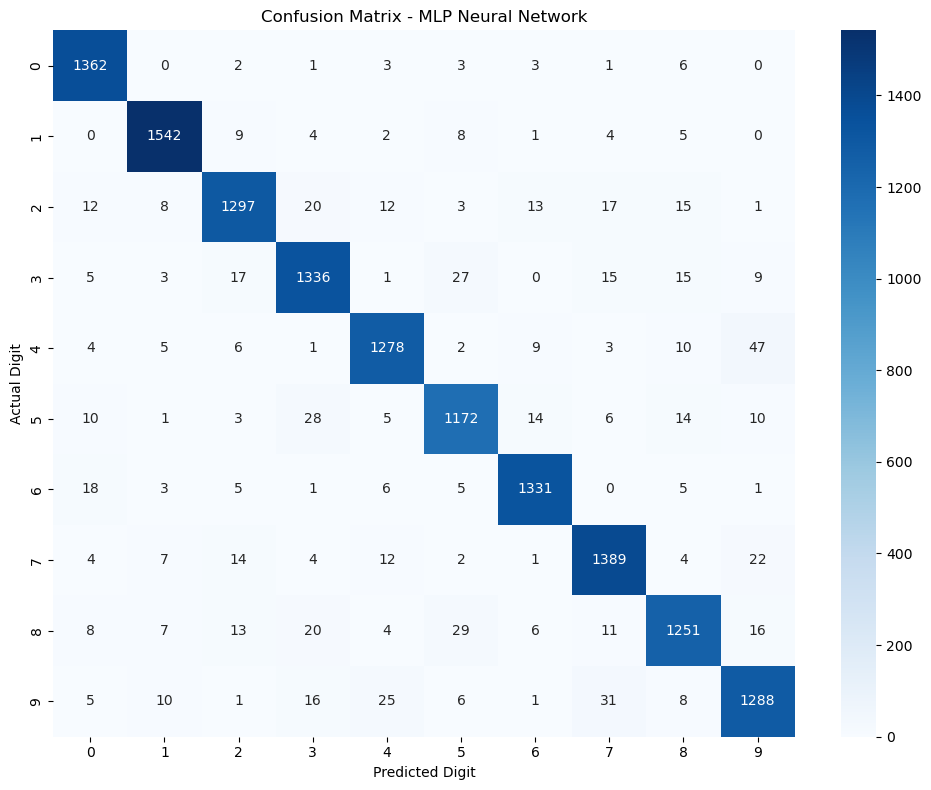

In [13]:
cm = confusion_matrix(y_test, mlp_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)
plt.title('Confusion Matrix - MLP Neural Network')
plt.ylabel('Actual Digit')
plt.xlabel('Predicted Digit')
plt.tight_layout()
plt.show()

# Step 13: Visualizing Correct and Wrong Predictions

Here we look at actual images the model predicted correctly 
and some it got wrong. Seeing the wrong predictions helps 
us understand why the model makes mistakes. Some handwritten 
digits genuinely look similar even to human eyes.

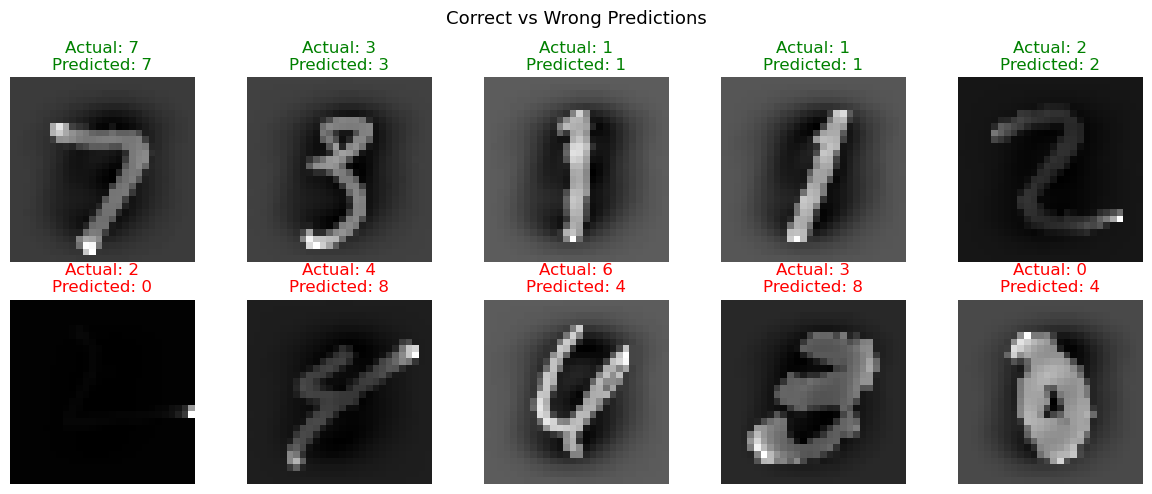

Total correct  : 13246
Total wrong    : 754
Accuracy       : 94.61%


In [14]:
y_pred = mlp_pred
correct = np.where(y_pred == y_test)[0]
incorrect = np.where(y_pred != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, idx in enumerate(correct[:5]):
    image = X_test[idx].reshape(28, 28)
    axes[0, i].imshow(image, cmap='gray')
    axes[0, i].set_title(f'Actual: {y_test[idx]}\nPredicted: {y_pred[idx]}', color='green')
    axes[0, i].axis('off')

for i, idx in enumerate(incorrect[:5]):
    image = X_test[idx].reshape(28, 28)
    axes[1, i].imshow(image, cmap='gray')
    axes[1, i].set_title(f'Actual: {y_test[idx]}\nPredicted: {y_pred[idx]}', color='red')
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Correct', fontsize=12, color='green')
axes[1, 0].set_ylabel('Wrong', fontsize=12, color='red')

plt.suptitle('Correct vs Wrong Predictions', fontsize=13)
plt.tight_layout()
plt.show()

print("Total correct  :", len(correct))
print("Total wrong    :", len(incorrect))
print(f"Accuracy       : {len(correct)/len(y_test)*100:.2f}%")

# Step 14: Saving the Model

We save the trained MLP model and the scaler so we can 
load them later for the interactive prediction app without 
needing to retrain everything from scratch.

In [15]:
import joblib

joblib.dump(mlp_model, 'handwriting_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model saved as handwriting_model.pkl")
print("Scaler saved as scaler.pkl")

Model saved as handwriting_model.pkl
Scaler saved as scaler.pkl


# Step 15: Interactive Handwritten Digit Recognizer

Here we build an interactive app where the user can enter 
any index number between 0 and 13999 to select an image 
from the test set. The app will display that image and 
predict which digit it is along with confidence scores 
for all 10 digits.

In [16]:
import ipywidgets as widgets
from IPython.display import display, clear_output

title = widgets.HTML("<h3 style='color:#2c3e50'>Handwritten Digit Recognizer</h3>")

index_input = widgets.BoundedIntText(
    value=0,
    min=0,
    max=13999,
    step=1,
    description='Image Index:',
    style={'description_width': '120px'},
    layout=widgets.Layout(width='300px')
)

button = widgets.Button(
    description='Recognize Digit',
    button_style='primary',
    layout=widgets.Layout(width='200px')
)

output = widgets.Output()

def recognize_digit(b):
    with output:
        clear_output()

        idx = index_input.value
        image = X_test[idx].reshape(28, 28)
        actual = y_test.iloc[idx] if hasattr(y_test, 'iloc') else y_test[idx]

        prediction = mlp_model.predict(X_test[idx].reshape(1, -1))[0]
        probabilities = mlp_model.predict_proba(X_test[idx].reshape(1, -1))[0]

        fig, axes = plt.subplots(1, 2, figsize=(10, 4))

        axes[0].imshow(image, cmap='gray')
        axes[0].axis('off')
        color = 'green' if prediction == actual else 'red'
        axes[0].set_title(
            f'Actual: {actual}  |  Predicted: {prediction}',
            color=color,
            fontsize=13
        )

        digits = list(range(10))
        colors = ['green' if d == prediction else '#3498db' for d in digits]
        bars = axes[1].bar(digits, probabilities * 100, color=colors)
        axes[1].set_title('Confidence for Each Digit')
        axes[1].set_xlabel('Digit')
        axes[1].set_ylabel('Confidence %')
        axes[1].set_xticks(digits)

        for bar, prob in zip(bars, probabilities):
            if prob > 0.05:
                axes[1].text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.5,
                    f'{prob*100:.1f}%',
                    ha='center',
                    fontsize=8
                )

        plt.tight_layout()
        plt.show()

        print("=" * 40)
        print(f"  Image Index  : {idx}")
        print(f"  Actual Digit : {actual}")
        print(f"  Predicted    : {prediction}")
        print(f"  Confidence   : {probabilities[prediction]*100:.1f}%")
        if prediction == actual:
            print("  Result       : Correct Prediction")
        else:
            print("  Result       : Wrong Prediction")
        print("=" * 40)

button.on_click(recognize_digit)

display(title, index_input, button, output)

HTML(value="<h3 style='color:#2c3e50'>Handwritten Digit Recognizer</h3>")

BoundedIntText(value=0, description='Image Index:', layout=Layout(width='300px'), max=13999, style=Description…

Button(button_style='primary', description='Recognize Digit', layout=Layout(width='200px'), style=ButtonStyle(…

Output()

1. Run the cell
2. Enter any number between 0 and 13999
3. Click Recognize Digit
4. See the image, prediction and confidence chart

Try these interesting ones:
- Change index until you find a wrong prediction
- Notice how confident the model is on easy digits
- Compare confidence on hard digits like 8 and 9

In [18]:
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np
import matplotlib.pyplot as plt

title = widgets.HTML("<h3 style='color:#2c3e50'>Test Your Own Handwritten Digit</h3>")

file_path_input = widgets.Text(
    value='digit.png',
    placeholder='Enter your image file name e.g. digit.png',
    description='Image File:',
    style={'description_width': '120px'},
    layout=widgets.Layout(width='400px')
)

button = widgets.Button(
    description='Predict My Digit',
    button_style='success',
    layout=widgets.Layout(width='200px')
)

output = widgets.Output()

def predict_my_image(b):
    with output:
        clear_output()

        filepath = file_path_input.value.strip()

        try:
            # Load image
            img = Image.open(filepath).convert('L')  # convert to grayscale

            # Resize to 28x28
            img = img.resize((28, 28))

            # Convert to numpy array
            img_array = np.array(img)

            # If background is white and digit is dark, invert it
            # MNIST has white digit on black background
            if img_array.mean() > 127:
                img_array = 255 - img_array

            # Normalize
            img_normalized = img_array / 255.0

            # Flatten to 784 values
            img_flat = img_normalized.flatten().reshape(1, -1)

            # Scale
            img_scaled = scaler.transform(img_flat)

            # Predict
            prediction = mlp_model.predict(img_scaled)[0]
            probabilities = mlp_model.predict_proba(img_scaled)[0]
            confidence = probabilities[prediction] * 100

            # Display
            fig, axes = plt.subplots(1, 2, figsize=(10, 4))

            axes[0].imshow(img_array, cmap='gray')
            axes[0].axis('off')
            axes[0].set_title(
                f'Your Image — Predicted: {prediction}',
                color='green',
                fontsize=13
            )

            digits = list(range(10))
            colors = ['green' if d == prediction else '#3498db' for d in digits]
            bars = axes[1].bar(digits, probabilities * 100, color=colors)
            axes[1].set_title('Confidence for Each Digit')
            axes[1].set_xlabel('Digit')
            axes[1].set_ylabel('Confidence %')
            axes[1].set_xticks(digits)

            for bar, prob in zip(bars, probabilities):
                if prob > 0.05:
                    axes[1].text(
                        bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + 0.5,
                        f'{prob*100:.1f}%',
                        ha='center',
                        fontsize=8
                    )

            plt.tight_layout()
            plt.show()

            print("=" * 40)
            print(f"  File       : {filepath}")
            print(f"  Predicted  : {prediction}")
            print(f"  Confidence : {confidence:.1f}%")
            print("=" * 40)

        except FileNotFoundError:
            print("File not found. Please check the file name and make sure")
            print("it is in the same folder as your notebook.")
        except Exception as e:
            print("Something went wrong:", str(e))

button.on_click(predict_my_image)

display(title, file_path_input, button, output)

HTML(value="<h3 style='color:#2c3e50'>Test Your Own Handwritten Digit</h3>")

Text(value='digit.png', description='Image File:', layout=Layout(width='400px'), placeholder='Enter your image…

Button(button_style='success', description='Predict My Digit', layout=Layout(width='200px'), style=ButtonStyle…

Output()